In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import seaborn as sns

In [4]:
df_district_demo = pd.read_csv(r'data/phonepe/District_demographics.csv')
df_district_txn = pd.read_csv(r'data/phonepe/District_Txn_&_Users.csv')
df_state_device = pd.read_csv(r'data/phonepe/State_Device_Data.csv')
df_state_txn = pd.read_csv(r'data/phonepe/State_Txn_And_users.csv')
df_state_txn_split = pd.read_csv(r'data/phonepe/State_Txn_Split.csv')


In [5]:
df_district_demo.head()
df_district_txn.head()
df_state_device.head()
df_state_txn.head()
df_state_txn_split.head()

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,"40,83,315","19,130",213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,"41,70,468","15,152",275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,"51,51,549","10,807",477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,"48,89,230","11,391",429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,"28,84,524","15,359",188,AP13,YSR


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,"11,39,849","2,159",262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,"9,31,663","2,108",632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,"5,688","1,25,60,249","2,208","5,846",0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,"1,120","30,72,437","2,743",351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,"13,17,863","1,597",911,0


,State,Year,Quarter,Brand,Registered Users,Percentage
0,Andaman & Nicobar Islands,2018,1,Xiaomi,"1,665",25%
1,Andaman & Nicobar Islands,2018,1,Samsung,"1,445",21%
2,Andaman & Nicobar Islands,2018,1,Vivo,982,15%
3,Andaman & Nicobar Islands,2018,1,Oppo,501,7%
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,5%


,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,"6,658","1,46,31,761","2,198","6,740",0
1,Andaman & Nicobar Islands,2018,2,"11,340","2,83,38,536","2,499","9,405",0
2,Andaman & Nicobar Islands,2018,3,"16,265","5,55,57,471","3,416","12,149",0
3,Andaman & Nicobar Islands,2018,4,"23,758","9,05,48,336","3,811","15,222",0
4,Andaman & Nicobar Islands,2019,1,"30,486","10,22,99,741","3,356","18,596",0


,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,"6,658","1,46,31,761","2,198","6,740",0
1,Andaman & Nicobar Islands,2018,2,"11,340","2,83,38,536","2,499","9,405",0
2,Andaman & Nicobar Islands,2018,3,"16,265","5,55,57,471","3,416","12,149",0
3,Andaman & Nicobar Islands,2018,4,"23,758","9,05,48,336","3,811","15,222",0
4,Andaman & Nicobar Islands,2019,1,"30,486","10,22,99,741","3,356","18,596",0


In [9]:
df_state_txn = pd.read_excel(r'data/phonepe/phonepe-pulse_raw-data_.xlsx', sheet_name = 'State_Txn and Users')
df_state_txn_split = pd.read_excel(r'data/phonepe/phonepe-pulse_raw-data_.xlsx', sheet_name = 'State_TxnSplit')
df_state_device = pd.read_excel(r'data/phonepe/phonepe-pulse_raw-data_.xlsx', sheet_name = 'State_DeviceData')
df_district_txn = pd.read_excel(r'data/phonepe/phonepe-pulse_raw-data_.xlsx', sheet_name = 'District_Txn and Users')
df_district_demo =  pd.read_excel(r'data/phonepe/phonepe-pulse_raw-data_.xlsx', sheet_name = 'District Demographics')

In [10]:
df_district_demo.head()
# State & District
df_district_txn.head()
# State, District, Year, Quarter
df_state_device.head()
# State	Year	Quarter	Brand
df_state_txn.head()
# State	Year	Quarter
df_state_txn_split.head()
# State	Year	Quarter	Transaction Type	

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0,275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,5151549,10807.0,477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,4889230,11391.0,429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,2884524,15359.0,188,AP13,YSR


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0


,State,Year,Quarter,Brand,Registered Users,Percentage
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.247033
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.214392
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.145697
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.074332
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.049258


,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0


,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,1.213866e+07,6487.790112
2,Andaman & Nicobar Islands,2018,1,Merchant payments,298,4.525072e+05,1518.480432
3,Andaman & Nicobar Islands,2018,1,Financial Services,33,1.060142e+04,321.255149
4,Andaman & Nicobar Islands,2018,1,Others,256,1.846899e+05,721.444790


In [14]:
## Explore the data
# Middle 10 rows - 

x = df_district_txn.shape[0]//2
df_district_txn.loc[x-5:x+5,:]




,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
5119,Madhya Pradesh,2021,2,Gwalior,MP20,7475892,1.546658e+10,2068.861331,753172,17980510
5120,Madhya Pradesh,2021,2,Harda,MP21,1022389,2.426741e+09,2373.598502,107671,6297529
5121,Madhya Pradesh,2021,2,Hoshangabad,MP22,2539274,5.124086e+09,2017.933375,298276,12814860
5122,Madhya Pradesh,2021,2,Indore,MP23,34159162,5.902681e+10,1727.993380,1892259,39059484
5123,Madhya Pradesh,2021,2,Jabalpur,MP24,6808088,1.287959e+10,1891.806811,695130,16368504
5124,Madhya Pradesh,2021,2,Jhabua,MP25,771669,1.681131e+09,2178.565418,104613,7481265
5125,Madhya Pradesh,2021,2,Katni,MP26,1723310,3.464169e+09,2010.183509,210578,9347591
5126,Madhya Pradesh,2021,2,Khargone,MP28,3055934,6.344133e+09,2076.004433,303115,17984042
5127,Madhya Pradesh,2021,2,Mandla,MP30,1048839,2.209589e+09,2106.700158,132963,10150247
5128,Madhya Pradesh,2021,2,Mandsaur,MP31,2219684,4.866468e+09,2192.414574,301823,12487874


In [16]:
# Display summary and statistics of all numerical columns in all 5 dataframes.

df_district_demo.describe(include = ['number'])

df_district_txn.describe(include = ['number'])

df_state_device.describe(include = ['number'])

df_state_txn.describe(include = ['number'])

df_state_txn_split.describe(include = ['number'])

,Population,Area (sq km),Density
count,7.420000e+02,742.000000,742.000000
mean,1.668555e+06,4395.373120,838.512129
std,1.458849e+06,4254.676124,2754.406896
min,0.000000e+00,0.000000,0.000000
25%,6.530815e+05,2039.750000,198.000000
50%,1.322359e+06,3402.500000,353.000000
75%,2.297440e+06,5432.750000,686.250000
max,1.008285e+07,45652.000000,36155.000000


,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,10248.000000,10248.000000,1.024800e+04,1.024800e+04,10244.000000,1.024800e+04,1.024800e+04
mean,2019.285714,2.357143,2.003607e+06,3.542311e+09,1909.796545,2.349591e+05,4.807117e+06
std,1.030208,1.108924,9.613466e+06,1.473154e+10,600.943349,4.605978e+05,1.562541e+07
min,2018.000000,1.000000,0.000000e+00,0.000000e+00,84.944283,2.200000e+01,0.000000e+00
25%,2018.000000,1.000000,1.031418e+05,1.756668e+08,1554.589051,3.619550e+04,0.000000e+00
50%,2019.000000,2.000000,3.763065e+05,6.784562e+08,1863.135530,1.067640e+05,6.403025e+05
75%,2020.000000,3.000000,1.272815e+06,2.377256e+09,2203.083552,2.573165e+05,4.346320e+06
max,2021.000000,4.000000,3.487128e+08,4.444224e+11,11209.980550,1.060461e+07,5.544197e+08


,Year,Quarter,Registered Users,Percentage
count,5544.000000,5544.000000,5.544000e+03,5544.000000
mean,2019.285714,2.357143,4.343183e+05,0.090909
std,1.030250,1.108970,9.056069e+05,0.083095
min,2018.000000,1.000000,1.000000e+01,0.006373
25%,2018.000000,1.000000,8.055750e+03,0.021588
50%,2019.000000,2.000000,7.442250e+04,0.056914
75%,2020.000000,3.000000,3.978875e+05,0.143626
max,2021.000000,4.000000,9.764252e+06,0.478367


,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,504.000000,504.000000,5.040000e+02,5.030000e+02,504.000000,5.040000e+02,5.040000e+02
mean,2019.285714,2.357143,4.074000e+07,7.083332e+10,1993.471543,4.777501e+06,9.774471e+07
std,1.031181,1.109971,8.228714e+07,1.440902e+11,607.464894,6.644496e+06,2.042376e+08
min,2018.000000,1.000000,7.780000e+02,1.928611e+06,0.000000,5.010000e+02,0.000000e+00
25%,2018.000000,1.000000,5.925578e+05,1.167157e+09,1598.910667,1.574202e+05,0.000000e+00
50%,2019.000000,2.000000,6.217487e+06,1.051605e+10,1861.380589,1.747914e+06,2.930574e+06
75%,2020.000000,3.000000,4.363675e+07,6.947045e+10,2259.087924,7.320945e+06,8.615022e+07
max,2021.000000,4.000000,5.736165e+08,1.027958e+12,3938.733850,3.966470e+07,1.208084e+09


,Year,Quarter,Transactions,Amount (INR),ATV (INR)
count,2514.000000,2514.000000,2.514000e+03,2.514000e+03,2514.000000
mean,2019.286794,2.358393,8.167446e+06,1.443978e+10,1349.927929
std,1.030807,1.109251,2.423645e+07,5.995054e+10,1534.866221
min,2018.000000,1.000000,2.000000e+00,3.439721e+01,17.198606
25%,2018.000000,1.000000,2.788075e+04,1.762412e+07,385.735827
50%,2019.000000,2.000000,2.687980e+05,1.901189e+08,720.940406
75%,2020.000000,3.000000,3.683230e+06,2.661248e+09,1352.790116
max,2021.000000,4.000000,2.795990e+08,8.721520e+11,7767.539936


In [18]:
# Display summary and statistics of all object columns in all 5 dataframes.

df_district_demo.describe(include = ['object'])

df_district_txn.describe(include = ['object'])

df_state_device.describe(include = ['object'])

df_state_txn.describe(include = ['object'])

df_state_txn_split.describe(include = ['object'])

,State,District,Headquarters,Code,Alternate Name
count,742,742,742,742,742
unique,36,736,733,742,733
top,Uttar Pradesh,Bijapur,Bangalore,AP01,South
freq,75,2,2,1,2


,State,District,Code
count,10248,10248,10220
unique,36,723,730
top,Uttar Pradesh,South,AN01
freq,1050,28,14


,State,Brand
count,5544,5544
unique,36,20
top,Andaman & Nicobar Islands,Xiaomi
freq,154,504


,State
count,504
unique,36
top,Andaman & Nicobar Islands
freq,14


,State,Transaction Type
count,2514,2514
unique,36,5
top,Andaman & Nicobar Islands,Recharge & bill payments
freq,70,504


In [19]:
# Identify missing values in each dataset
df_district_demo.isna().sum()

df_district_txn.isna().sum()

df_state_device.isna().sum()

df_state_txn.isna().sum()

df_state_txn_split.isna().sum()


State             0
District          0
Headquarters      0
Population        0
Area (sq km)      0
Density           0
Code              0
Alternate Name    0
dtype: int64

State                0
Year                 0
Quarter              0
District             0
Code                28
Transactions         0
Amount (INR)         0
ATV (INR)            4
Registered Users     0
App Opens            0
dtype: int64

State               0
Year                0
Quarter             0
Brand               0
Registered Users    0
Percentage          0
dtype: int64

State               0
Year                0
Quarter             0
Transactions        0
Amount (INR)        1
ATV (INR)           0
Registered Users    0
App Opens           0
dtype: int64

State               0
Year                0
Quarter             0
Transaction Type    0
Transactions        0
Amount (INR)        0
ATV (INR)           0
dtype: int64

In [20]:
# Identify missing values in each dataset
df_district_demo.isna().mean()

df_district_txn.isna().mean()

df_state_device.isna().mean()

df_state_txn.isna().mean()

df_state_txn_split.isna().mean()


State             0.0
District          0.0
Headquarters      0.0
Population        0.0
Area (sq km)      0.0
Density           0.0
Code              0.0
Alternate Name    0.0
dtype: float64

State               0.000000
Year                0.000000
Quarter             0.000000
District            0.000000
Code                0.002732
Transactions        0.000000
Amount (INR)        0.000000
ATV (INR)           0.000390
Registered Users    0.000000
App Opens           0.000000
dtype: float64

State               0.0
Year                0.0
Quarter             0.0
Brand               0.0
Registered Users    0.0
Percentage          0.0
dtype: float64

State               0.000000
Year                0.000000
Quarter             0.000000
Transactions        0.000000
Amount (INR)        0.001984
ATV (INR)           0.000000
Registered Users    0.000000
App Opens           0.000000
dtype: float64

State               0.0
Year                0.0
Quarter             0.0
Transaction Type    0.0
Transactions        0.0
Amount (INR)        0.0
ATV (INR)           0.0
dtype: float64

In [21]:
df_district_txn.isna().mean().idxmax()

'Code'

In [22]:
df_state_device.columns.tolist()

['State', 'Year', 'Quarter', 'Brand', 'Registered Users', 'Percentage']

In [24]:
# Fid total number of states and total number of districts
df_state_device['State'].nunique()
df_district_txn['State'].nunique()

# Similarly find number of districts.

36

36

In [27]:
# Calculate the total number of transactions and total transaction amount for each state over the years
df_state_txn.groupby(['State', 'Year']).agg(total_transactions = ('Transactions', 'sum'), total_amount = ('Amount (INR)', 'sum')).reset_index()

,State,Year,total_transactions,total_amount
0,Andaman & Nicobar Islands,2018,58021,1.890761e+08
1,Andaman & Nicobar Islands,2019,133104,4.734648e+08
2,Andaman & Nicobar Islands,2020,446274,1.296423e+09
3,Andaman & Nicobar Islands,2021,586166,1.682854e+09
4,Andhra Pradesh,2018,77779112,1.220720e+11
...,...,...,...,...
139,Uttarakhand,2021,44608834,7.727901e+10
140,West Bengal,2018,120011635,1.115887e+11
141,West Bengal,2019,257900590,2.660145e+11
142,West Bengal,2020,304222327,5.527316e+11


In [31]:
# Identify the top 5 states with the highest transaction volumes and the top 5 states with the lowest transaction volumes
df_state_txn.groupby(['State'])['Transactions'].sum().idxmax()
df_state_txn.groupby(['State'])['Transactions'].sum().nlargest(5)

'Karnataka'

State
Karnataka         2981044533
Maharashtra       2833670154
Telangana         2347430243
Andhra Pradesh    1781091169
Rajasthan         1382918930
Name: Transactions, dtype: int64

In [34]:
# Identify the most common transaction types in each state Year and quarter
top_idx = df_state_txn_split.groupby(['State', 'Year', 'Quarter'])['Transactions'].idxmax()

df_state_txn_split.loc[top_idx]


,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921
5,Andaman & Nicobar Islands,2018,2,Recharge & bill payments,6735,2.320945e+06,344.609463
10,Andaman & Nicobar Islands,2018,3,Recharge & bill payments,8636,4.343505e+06,502.953320
15,Andaman & Nicobar Islands,2018,4,Recharge & bill payments,11517,5.450550e+06,473.261224
20,Andaman & Nicobar Islands,2019,1,Recharge & bill payments,15263,6.611460e+06,433.169093
...,...,...,...,...,...,...,...
2489,West Bengal,2020,2,Peer-to-peer payments,24855687,8.498400e+10,3419.096979
2494,West Bengal,2020,3,Peer-to-peer payments,37556349,1.331207e+11,3544.558502
2499,West Bengal,2020,4,Peer-to-peer payments,46437233,1.663919e+11,3583.156529
2504,West Bengal,2021,1,Peer-to-peer payments,53869075,2.022402e+11,3754.292226


In [39]:
# Identify the most common transaction types in each state Year
transactions =df_state_txn_split.groupby(['State', 'Year', 'Transaction Type'])['Transactions'].sum().reset_index()
rows = transactions.groupby(['State', 'Year'])['Transactions'].idxmax()
transactions.loc[rows]

,State,Year,Transaction Type,Transactions
4,Andaman & Nicobar Islands,2018,Recharge & bill payments,31088
9,Andaman & Nicobar Islands,2019,Recharge & bill payments,60009
14,Andaman & Nicobar Islands,2020,Recharge & bill payments,196514
18,Andaman & Nicobar Islands,2021,Peer-to-peer payments,238230
23,Andhra Pradesh,2018,Peer-to-peer payments,41504323
...,...,...,...,...
696,Uttarakhand,2021,Merchant payments,17528156
703,West Bengal,2018,Peer-to-peer payments,71705443
708,West Bengal,2019,Peer-to-peer payments,136220653
713,West Bengal,2020,Peer-to-peer payments,137306673


In [46]:
# Identify the most common transaction types in each state
transaction = df_state_txn_split.groupby(['State', 'Transaction Type'])['Transactions'].sum().reset_index()
rows = transaction.groupby(['State'])['Transactions'].idxmax()
transaction.loc[rows]


,State,Transaction Type,Transactions
4,Andaman & Nicobar Islands,Recharge & bill payments,492641
8,Andhra Pradesh,Peer-to-peer payments,944411081
14,Arunachal Pradesh,Recharge & bill payments,3868464
18,Assam,Peer-to-peer payments,55178220
23,Bihar,Peer-to-peer payments,370640181
28,Chandigarh,Peer-to-peer payments,11132019
33,Chhattisgarh,Peer-to-peer payments,99454667
38,Dadra & Nagar Haveli and Daman & Diu,Peer-to-peer payments,5006285
41,Delhi,Merchant payments,414408596
48,Goa,Peer-to-peer payments,10193184


In [52]:
# Determine the device brand with the highest number of registered users in each state
users = df_state_device.groupby(['State', 'Brand'])['Registered Users'].sum().reset_index()
rows = users.groupby(['State'])['Registered Users'].idxmax()
users.loc[rows]

,State,Brand,Registered Users
11,Andaman & Nicobar Islands,Xiaomi,97889
22,Andhra Pradesh,Xiaomi,40061549
34,Arunachal Pradesh,Xiaomi,437803
46,Assam,Xiaomi,6979357
60,Bihar,Xiaomi,33721314
73,Chandigarh,Xiaomi,896628
85,Chhattisgarh,Xiaomi,8763373
98,Dadra & Nagar Haveli and Daman & Diu,Xiaomi,638834
109,Delhi,Xiaomi,24114984
120,Goa,Xiaomi,1208672


In [57]:
# Calculate the total number of transactions, total transaction amount, 
# and total registered users in each state by summing up the values from the district level data

df_district = df_district_txn.groupby(['State']).agg(district_transactions = ('Transactions', 'sum'), 
                                      district_transaction_amt = ('Amount (INR)', 'sum'),
                                      district_reg_users = ('Registered Users', 'sum')).reset_index()


# Calculate the total number of transactions, total transaction amount, 
# and total registered users in each state by summing up the values from the State level data

df_state = df_state_txn.groupby(['State']).agg(state_transactions = ('Transactions', 'sum'), 
                                      state_transaction_amt = ('Amount (INR)', 'sum'),
                                      state_reg_users = ('Registered Users', 'sum')).reset_index()


df_combined = df_state.merge(df_district, how = 'left', on = ['State'])

In [59]:
(df_combined['state_transactions'] == df_combined['state_transactions']).mean()
# similarly check for other columns

1.0

In [60]:
df_state_txn

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0
...,...,...,...,...,...,...,...,...
499,West Bengal,2020,2,57676797,1.000994e+11,1735.523418,13222022,198589332
500,West Bengal,2020,3,79954504,1.568134e+11,1961.282329,14448366,246554831
501,West Bengal,2020,4,100340645,1.991655e+11,1984.893473,15662093,291721919
502,West Bengal,2021,1,118254052,2.429372e+11,2054.366877,16808799,316832674


In [69]:
# calculate the average transaction amount per user for each state

df_transactions = df_state_txn.groupby('State').agg(total_transactions = ('Transactions', 'sum'), 
                                  total_amount = ('Amount (INR)', 'sum')).reset_index()
df_transactions['avg_transaction_per_user'] = df_transactions['total_amount']/df_transactions['total_transactions']
df_transactions

df_transactions.nlargest(5, columns = 'avg_transaction_per_user')
df_transactions.nsmallest(5, columns = 'avg_transaction_per_user')

,State,total_transactions,total_amount,avg_transaction_per_user
0,Andaman & Nicobar Islands,1223565,3.641818e+09,2976.399178
1,Andhra Pradesh,1781091169,3.187847e+12,1789.828350
2,Arunachal Pradesh,8043799,2.225183e+10,2766.333539
3,Assam,123577981,2.814087e+11,2277.175192
4,Bihar,713643889,1.639579e+12,2297.474906
5,Chandigarh,25516542,5.371208e+10,2104.990740
6,Chhattisgarh,241908549,4.156353e+11,1718.150602
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,1497.232192
8,Delhi,1011031124,1.649942e+12,1631.940078
9,Goa,24481604,4.427187e+10,1808.372977


,State,total_transactions,total_amount,avg_transaction_per_user
17,Ladakh,1880109,6.606978e+09,3514.146494
0,Andaman & Nicobar Islands,1223565,3.641818e+09,2976.399178
23,Mizoram,2162776,6.317141e+09,2920.848685
21,Manipur,12318043,3.579325e+10,2905.757931
24,Nagaland,5864977,1.638757e+10,2794.140997


,State,total_transactions,total_amount,avg_transaction_per_user
15,Karnataka,2981044533,4.361396e+12,1463.042846
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,1497.232192
20,Maharashtra,2833670154,4.290995e+12,1514.288897
35,West Bengal,942286041,1.452707e+12,1541.683482
8,Delhi,1011031124,1.649942e+12,1631.940078


In [70]:
df_state_txn

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0
...,...,...,...,...,...,...,...,...
499,West Bengal,2020,2,57676797,1.000994e+11,1735.523418,13222022,198589332
500,West Bengal,2020,3,79954504,1.568134e+11,1961.282329,14448366,246554831
501,West Bengal,2020,4,100340645,1.991655e+11,1984.893473,15662093,291721919
502,West Bengal,2021,1,118254052,2.429372e+11,2054.366877,16808799,316832674


In [74]:
app_opens = df_state_txn.groupby(['State', 'Year', 'Quarter'])['App Opens'].sum().reset_index()
app_opens

,State,Year,Quarter,App Opens
0,Andaman & Nicobar Islands,2018,1,0
1,Andaman & Nicobar Islands,2018,2,0
2,Andaman & Nicobar Islands,2018,3,0
3,Andaman & Nicobar Islands,2018,4,0
4,Andaman & Nicobar Islands,2019,1,0
...,...,...,...,...
499,West Bengal,2020,2,198589332
500,West Bengal,2020,3,246554831
501,West Bengal,2020,4,291721919
502,West Bengal,2021,1,316832674


In [89]:
state = 'Andhra Pradesh'
app_opens  = app_opens.sort_values(['Year', 'Quarter'])
app_opens['Year-Quarter'] = app_opens['Year'].astype(str)  + '-0' +  app_opens['Quarter'].astype(str)

<Figure size 1152x648 with 0 Axes>

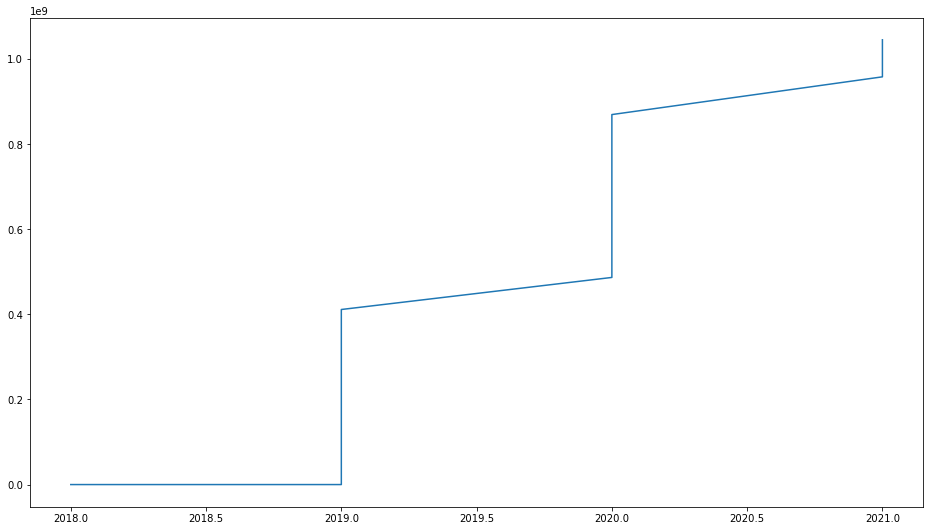

In [90]:
plt.figure(figsize = (16, 9))
df_sub = app_opens[app_opens['State'] == state]
plt.plot(df_sub['Year'], df_sub['App Opens'])

In [95]:
df_state_txn_split['YYYYQQ'] = (df_state_txn_split['Year'].astype(str) + '0'+ df_state_txn_split['Quarter'].astype(str)).astype(int)

In [115]:
rows = df_state_txn_split.groupby(['State', 'Transaction Type'])['YYYYQQ'].idxmax()

df_sub = df_state_txn_split.loc[rows]
df_sub

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR),YYYYQQ
68,Andaman & Nicobar Islands,2021,2,Financial Services,960,2.038522e+06,2123.459910,202102
67,Andaman & Nicobar Islands,2021,2,Merchant payments,85143,1.037074e+08,1218.037989,202102
69,Andaman & Nicobar Islands,2021,2,Others,1628,1.327080e+06,815.159740,202102
65,Andaman & Nicobar Islands,2021,2,Peer-to-peer payments,132772,7.483820e+08,5636.595402,202102
66,Andaman & Nicobar Islands,2021,2,Recharge & bill payments,120911,4.369196e+07,361.356380,202102
...,...,...,...,...,...,...,...,...
2512,West Bengal,2021,2,Financial Services,190537,1.864665e+08,978.636630,202102
2510,West Bengal,2021,2,Merchant payments,41696787,3.478787e+10,834.305703,202102
2513,West Bengal,2021,2,Others,549353,3.167447e+08,576.577748,202102
2509,West Bengal,2021,2,Peer-to-peer payments,64661051,2.308123e+11,3569.572026,202102


<Figure size 1152x648 with 0 Axes>

<AxesSubplot:xlabel='State', ylabel='Transactions'>

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
        34, 35]),
 [Text(0, 0, 'Andaman & Nicobar Islands'),
  Text(1, 0, 'Andhra Pradesh'),
  Text(2, 0, 'Arunachal Pradesh'),
  Text(3, 0, 'Assam'),
  Text(4, 0, 'Bihar'),
  Text(5, 0, 'Chandigarh'),
  Text(6, 0, 'Chhattisgarh'),
  Text(7, 0, 'Dadra & Nagar Haveli and Daman & Diu'),
  Text(8, 0, 'Delhi'),
  Text(9, 0, 'Goa'),
  Text(10, 0, 'Gujarat'),
  Text(11, 0, 'Haryana'),
  Text(12, 0, 'Himachal Pradesh'),
  Text(13, 0, 'Jammu & Kashmir'),
  Text(14, 0, 'Jharkhand'),
  Text(15, 0, 'Karnataka'),
  Text(16, 0, 'Kerala'),
  Text(17, 0, 'Ladakh'),
  Text(18, 0, 'Lakshadweep'),
  Text(19, 0, 'Madhya Pradesh'),
  Text(20, 0, 'Maharashtra'),
  Text(21, 0, 'Manipur'),
  Text(22, 0, 'Meghalaya'),
  Text(23, 0, 'Mizoram'),
  Text(24, 0, 'Nagaland'),
  Text(25, 0, 'Odisha'),
  Text(26, 0, 'Puducherry'),
  Text(27, 0, 'Punjab'),
  Text(28, 0

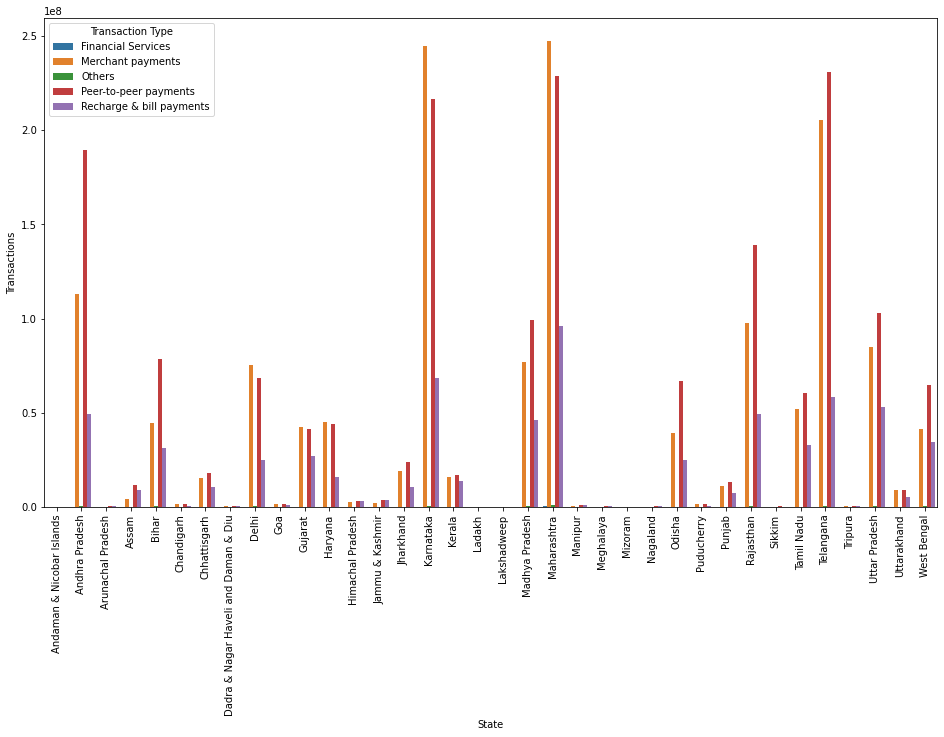

In [116]:
plt.figure(figsize = (16, 9))
sns.barplot(x = df_sub['State'], y = df_sub['Transactions'], hue = df_sub['Transaction Type'])
plt.xticks(rotation = 90)

dtype('int64')